# Лабораторна робота №2. Апроксимація та інтерполяція функцій

Варіант 23.

## Вихідні дані

Шість вибірок yₙ з таблиці варіанту, n = 1…6. Основну частоту взято ω₀ = 1 рад/с, тоді період T₀ = 2π с, а інтервал дискретизації Tₐ = 2π/(Nω₀) = π/3 с, tₙ = n·Tₐ.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

variant_number = 23
sample_numbers = np.arange(1, 7)
sample_values = np.array([0.3, 1.3, 2.1, 3.2, 4.1, 4.5])
sample_count = len(sample_values)

# The guide does not give the fundamental frequency, so one period is taken as 2 * pi seconds.
fundamental_frequency = 1.0
signal_period = 2 * np.pi / fundamental_frequency
sampling_period = signal_period / sample_count  # Ta = 2 * pi / (N * w0) from the task
sample_times = sample_numbers * sampling_period


def clean(value):
    """Round away float noise, so a tiny negative number prints as 0.000000, not -0.000000."""
    return np.round(value, 10) + 0.0


print(f"Variant {variant_number}, N = {sample_count}")
print("n:  ", sample_numbers)
print("y_n:", sample_values)
print(f"w0 = {fundamental_frequency:.6f} rad/s, T0 = {signal_period:.6f} s, Ta = {sampling_period:.6f} s")

Variant 23, N = 6
n:   [1 2 3 4 5 6]
y_n: [0.3 1.3 2.1 3.2 4.1 4.5]
w0 = 1.000000 rad/s, T0 = 6.283185 s, Ta = 1.047198 s


## Завдання 1. Ряд Фур'є вручну

Коефіцієнти рахуються за формулами (42), (48), (49) методички: a₀ = (2/N)Σyₙ, aₖ = (2/N)Σyₙcos(kω₀tₙ), bₖ = (2/N)Σyₙsin(kω₀tₙ). За умовою (35) для N = 6 є дві повні гармоніки, а третя (k = N/2) є гармонікою Найквіста: її синус у вузлах дорівнює нулю, тому для a₃ береться множник 1/N. Тоді ряд (33) проходить точно через усі вибірки.

In [2]:
# Condition (35): N samples give at most (N - 1) / 2 full harmonic pairs. For N = 6 that is 2 pairs,
# and the third harmonic is the Nyquist one: its sine is zero at every sample, only the cosine is left.
highest_harmonic = sample_count // 2
harmonic_numbers = np.arange(1, highest_harmonic + 1)

constant_coefficient = 2 / sample_count * np.sum(sample_values)  # formula (42)
fourier_cosine_coefficients = np.zeros(highest_harmonic)
fourier_sine_coefficients = np.zeros(highest_harmonic)
for harmonic_index, harmonic_number in enumerate(harmonic_numbers):
    phases = harmonic_number * fundamental_frequency * sample_times
    # Formulas (48) and (49). The Nyquist cosine would be counted twice with 2/N, so it gets 1/N.
    scale = 1 / sample_count if harmonic_number == highest_harmonic else 2 / sample_count
    fourier_cosine_coefficients[harmonic_index] = scale * np.sum(sample_values * np.cos(phases))
    fourier_sine_coefficients[harmonic_index] = scale * np.sum(sample_values * np.sin(phases))


def evaluate_fourier_series(time_values):
    """Value of the series (33): a0 / 2 plus the cosine and sine terms of every harmonic."""
    result = np.full_like(time_values, constant_coefficient / 2, dtype=float)
    for harmonic_index, harmonic_number in enumerate(harmonic_numbers):
        phases = harmonic_number * fundamental_frequency * time_values
        result += fourier_cosine_coefficients[harmonic_index] * np.cos(phases)
        result += fourier_sine_coefficients[harmonic_index] * np.sin(phases)
    return result


fourier_at_samples = evaluate_fourier_series(sample_times)
fourier_node_error = np.max(np.abs(fourier_at_samples - sample_values))

print(f"a_0 = {constant_coefficient:.6f}")
for harmonic_index, harmonic_number in enumerate(harmonic_numbers):
    print(f"a_{harmonic_number} = {clean(fourier_cosine_coefficients[harmonic_index]):10.6f},"
          f" b_{harmonic_number} = {clean(fourier_sine_coefficients[harmonic_index]):10.6f}")
print(f"{'n':>3} {'t_n':>10} {'y_n':>10} {'f_R(t_n)':>10}")
for sample_index in range(sample_count):
    print(f"{sample_numbers[sample_index]:>3} {sample_times[sample_index]:10.6f}"
          f" {sample_values[sample_index]:10.6f} {fourier_at_samples[sample_index]:10.6f}")
print(f"max |f_R(t_n) - y_n| = {fourier_node_error:.1e}")

a_0 = 5.166667
a_1 =   0.783333, b_1 =  -1.645448
a_2 =   0.716667, b_2 =  -0.548483
a_3 =   0.416667, b_3 =   0.000000
  n        t_n        y_n   f_R(t_n)
  1   1.047198   0.300000   0.300000
  2   2.094395   1.300000   1.300000
  3   3.141593   2.100000   2.100000
  4   4.188790   3.200000   3.200000
  5   5.235988   4.100000   4.100000
  6   6.283185   4.500000   4.500000
max |f_R(t_n) - y_n| = 1.8e-15


## Перевірка через numpy.fft.fft

aₖ = (2/N)·Re, bₖ = −(2/N)·Im від ДПФ вибірок. Оскільки numpy рахує відліки від 0, а в таблиці вони від 1, спектр множиться на e^(−j2πk/N).

In [3]:
# np.fft.fft numbers the samples from 0, the task numbers them from 1. Multiplying by
# exp(-j * 2 * pi * k / N) moves every sample one step, so the sums match formulas (48) and (49).
spectrum = np.fft.fft(sample_values)
shift = np.exp(-2j * np.pi * np.arange(sample_count) / sample_count)
shifted_spectrum = spectrum * shift
library_constant_coefficient = 2 / sample_count * spectrum[0].real
library_cosine_coefficients = np.zeros(highest_harmonic)
library_sine_coefficients = np.zeros(highest_harmonic)
for harmonic_index, harmonic_number in enumerate(harmonic_numbers):
    scale = 1 / sample_count if harmonic_number == highest_harmonic else 2 / sample_count
    library_cosine_coefficients[harmonic_index] = scale * shifted_spectrum[harmonic_number].real
    library_sine_coefficients[harmonic_index] = -scale * shifted_spectrum[harmonic_number].imag

fourier_difference = max(
    abs(constant_coefficient - library_constant_coefficient),
    np.max(np.abs(fourier_cosine_coefficients - library_cosine_coefficients)),
    np.max(np.abs(fourier_sine_coefficients - library_sine_coefficients)),
)
print(f"np.fft.fft: a_0 = {library_constant_coefficient:.6f}")
for harmonic_index, harmonic_number in enumerate(harmonic_numbers):
    print(f"np.fft.fft: a_{harmonic_number} = {clean(library_cosine_coefficients[harmonic_index]):10.6f},"
          f" b_{harmonic_number} = {clean(library_sine_coefficients[harmonic_index]):10.6f}")
print(f"max |hand - fft| = {fourier_difference:.1e}")

np.fft.fft: a_0 = 5.166667
np.fft.fft: a_1 =   0.783333, b_1 =  -1.645448
np.fft.fft: a_2 =   0.716667, b_2 =  -0.548483
np.fft.fft: a_3 =   0.416667, b_3 =   0.000000
max |hand - fft| = 1.2e-15


## Завдання 2. Експоненціальна апроксимація вручну

f(x) = e^(A+Bx), xₙ = 0,1·23·n. Після логарифмування (52) залежність стає лінійною, і A, B рахуються методом найменших квадратів за формулами (55) і (56).

In [4]:
sample_x = 0.1 * variant_number * sample_numbers  # x_n = 0.1 * k * n, k is the variant number
log_values = np.log(sample_values)  # formula (52): after the logarithm the model is a straight line

sum_x = np.sum(sample_x)
sum_x2 = np.sum(sample_x**2)
sum_log_y = np.sum(log_values)
sum_x_log_y = np.sum(sample_x * log_values)

slope = (sum_x_log_y - sum_x * sum_log_y / sample_count) / (sum_x2 - sum_x**2 / sample_count)  # formula (56)
intercept = sum_log_y / sample_count - slope * sum_x / sample_count  # formula (55)


def evaluate_exponential(x_values):
    """Value of f(x) = exp(A + B * x)."""
    return np.exp(intercept + slope * x_values)


exponential_at_samples = evaluate_exponential(sample_x)
exponential_rms_error = np.sqrt(np.mean((exponential_at_samples - sample_values) ** 2))

print("x_n:", np.round(sample_x, 6))
print("ln y_n:", np.round(log_values, 6))
print(f"Sum x = {sum_x:.4f}, sum x^2 = {sum_x2:.4f}, sum ln y = {sum_log_y:.6f}, sum x ln y = {sum_x_log_y:.6f}")
print(f"A = {intercept:.6f}, B = {slope:.6f}")
print(f"f(x) = exp({intercept:.6f} + {slope:.6f}x)")
print("f(x_n):", np.round(exponential_at_samples, 6))
print(f"RMS error = {exponential_rms_error:.6f}")

x_n: [ 2.3  4.6  6.9  9.2 11.5 13.8]
ln y_n: [-1.203973  0.262364  0.741937  1.163151  1.410987  1.504077]
Sum x = 48.3000, sum x^2 = 481.3900, sum ln y = 3.878544, sum x ln y = 51.240712
A = -1.094309, B = 0.216240
f(x) = exp(-1.094309 + 0.216240x)
f(x_n): [0.550484 0.905195 1.488469 2.447581 4.024709 6.618077]
RMS error = 0.970450


## Перевірка через numpy.polyfit

Пряма ln y = A + Bx через numpy.polyfit першого степеня.

In [5]:
# np.polyfit returns the highest power first: the slope B, then the intercept A.
library_slope, library_intercept = np.polyfit(sample_x, log_values, 1)
exponential_difference = max(abs(intercept - library_intercept), abs(slope - library_slope))
print(f"np.polyfit: A = {library_intercept:.6f}, B = {library_slope:.6f}")
print(f"|hand - polyfit| for A = {abs(intercept - library_intercept):.1e}")
print(f"|hand - polyfit| for B = {abs(slope - library_slope):.1e}")
print(f"max |hand - polyfit| = {exponential_difference:.1e}")

np.polyfit: A = -1.094309, B = 0.216240
|hand - polyfit| for A = 6.7e-16
|hand - polyfit| for B = 1.9e-16
max |hand - polyfit| = 6.7e-16


## Завдання 3. Графіки

Ліворуч ряд Фур'є на двох періодах разом із вибірками, праворуч експоненціальна крива і вихідні дані.

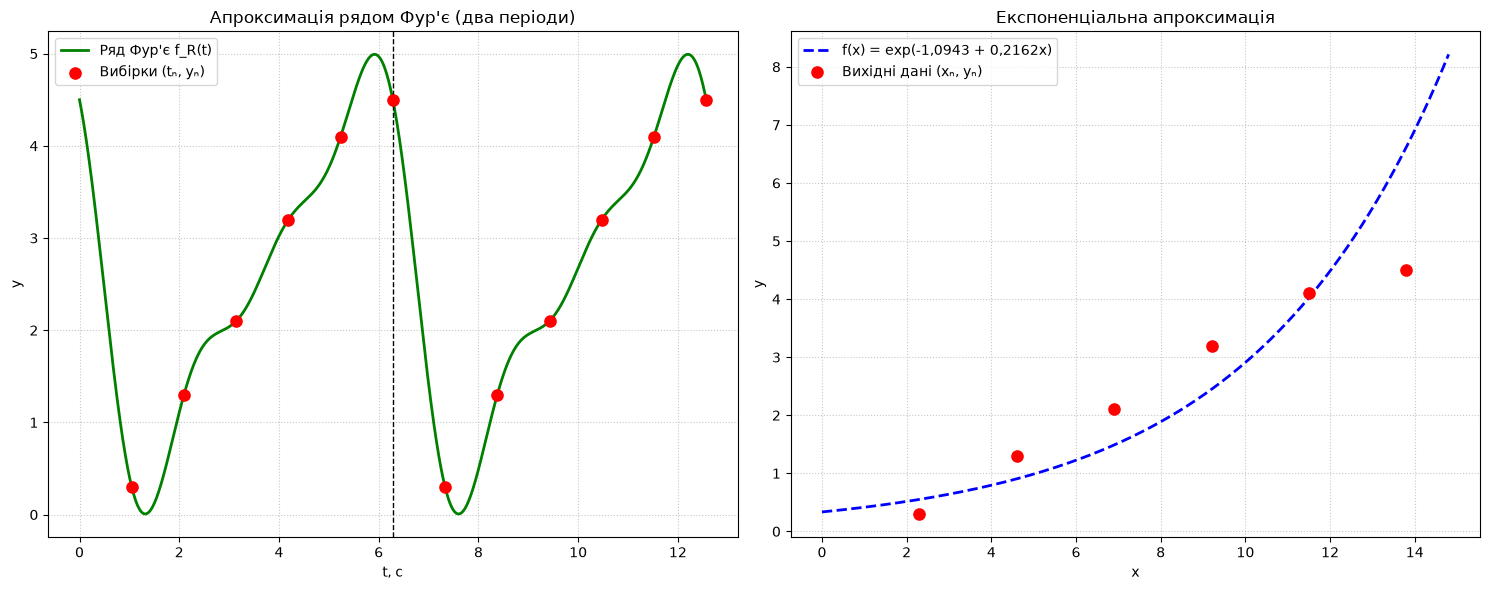

In [6]:
dense_times = np.linspace(0, 2 * signal_period, 1000)
dense_x = np.linspace(0, sample_x[-1] + 1, 500)

figure, (fourier_axis, exponential_axis) = plt.subplots(1, 2, figsize=(15, 6))
# Two periods with the same samples repeated, to show that the series is periodic.
fourier_axis.plot(dense_times, evaluate_fourier_series(dense_times), color="green", linewidth=2,
                  label="Ряд Фур'є f_R(t)")
fourier_axis.scatter(np.concatenate([sample_times, sample_times + signal_period]), np.tile(sample_values, 2),
                     color="red", s=65, zorder=5, label="Вибірки (tₙ, yₙ)")
fourier_axis.axvline(signal_period, color="black", linestyle="--", linewidth=1)
fourier_axis.set_title("Апроксимація рядом Фур'є (два періоди)")
fourier_axis.set_xlabel("t, с")
fourier_axis.set_ylabel("y")
fourier_axis.legend()
fourier_axis.grid(linestyle=":", alpha=0.7)

exponential_axis.plot(dense_x, evaluate_exponential(dense_x), "--", color="blue", linewidth=2,
                      label=f"f(x) = exp({intercept:.4f} + {slope:.4f}x)".replace(".", ","))
exponential_axis.scatter(sample_x, sample_values, color="red", s=65, zorder=5, label="Вихідні дані (xₙ, yₙ)")
exponential_axis.set_title("Експоненціальна апроксимація")
exponential_axis.set_xlabel("x")
exponential_axis.set_ylabel("y")
exponential_axis.legend()
exponential_axis.grid(linestyle=":", alpha=0.7)

plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/fourier_exponential.png", dpi=180)
plt.show()

## Підсумок

Коефіцієнти обох апроксимацій і найбільша різниця між ручним розрахунком та бібліотекою.

In [7]:
largest_difference = max(fourier_difference, exponential_difference)
print(f"Fourier: a_0 = {constant_coefficient:.6f}, a_k = {np.round(clean(fourier_cosine_coefficients), 6)},"
      f" b_k = {np.round(clean(fourier_sine_coefficients), 6)}")
print(f"Fourier series passes through all samples: max error {fourier_node_error:.1e}")
print(f"Exponential: f(x) = exp({intercept:.6f} + {slope:.6f}x), RMS error {exponential_rms_error:.6f}")
print(f"Largest |hand - library| difference: {largest_difference:.1e}")

Fourier: a_0 = 5.166667, a_k = [0.783333 0.716667 0.416667], b_k = [-1.645448 -0.548483  0.      ]
Fourier series passes through all samples: max error 1.8e-15
Exponential: f(x) = exp(-1.094309 + 0.216240x), RMS error 0.970450
Largest |hand - library| difference: 1.2e-15
